## Phần 1 — Import

In [1]:
# ── Cell 1: Import thư viện ───────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split, LeaveOneOut, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, accuracy_score

## Phần 2 — Dữ liệu mẫu

In [2]:
# ── Cell 2: Corpus 6 văn bản ──────────────────────────────────────────────
corpus_base = [
    "I love NLP",
    "I love AI",
    "NLP is interesting",
    "AI is powerful",
    "Machine learning is part of AI",
    "Deep learning belongs to NLP"
]

## Phần 3 — Bag-of-Words (BoW)
`CountVectorizer` mặc định: đưa về chữ thường và chỉ giữ token có **từ 2 ký tự trở lên** (`token_pattern=r"(?u)\b\w\w+\b"`), nên từ "I" bị bỏ khỏi vocabulary.

In [3]:
# ── Cell 3: BoW trên 6 văn bản ────────────────────────────────────────────
vectorizer = CountVectorizer()
X_bow_base = vectorizer.fit_transform(corpus_base)

print("Vocabulary:")
print(vectorizer.get_feature_names_out())
print("\nBoW Matrix:", X_bow_base.shape)
print(X_bow_base.toarray())

Vocabulary:
['ai' 'belongs' 'deep' 'interesting' 'is' 'learning' 'love' 'machine'
 'nlp' 'of' 'part' 'powerful' 'to']

BoW Matrix: (6, 13)
[[0 0 0 0 0 0 1 0 1 0 0 0 0]
 [1 0 0 0 0 0 1 0 0 0 0 0 0]
 [0 0 0 1 1 0 0 0 1 0 0 0 0]
 [1 0 0 0 1 0 0 0 0 0 0 1 0]
 [1 0 0 0 1 1 0 1 0 1 1 0 0]
 [0 1 1 0 0 1 0 0 1 0 0 0 1]]


## Bài 1 — Thêm 2 câu vào corpus
* Thêm vào corpus 2 câu
* Nhận xét sự thay đổi
* Vì sao vector lại sparse

In [4]:
# ── Cell 4: Thêm 2 câu và tính lại BoW ────────────────────────────────────
corpus = corpus_base + ["AI and NLP are related", "Deep learning is powerful"]   # không sửa corpus_base để so sánh được

vectorizer = CountVectorizer()
X_bow = vectorizer.fit_transform(corpus)

print("Vocabulary:")
print(vectorizer.get_feature_names_out())
print("\nBoW Matrix:", X_bow.shape)
print(X_bow.toarray())

print(f"\nKích thước: {X_bow_base.shape} -> {X_bow.shape}")
print("Từ mới:", sorted(set(vectorizer.get_feature_names_out()) - set(CountVectorizer().fit(corpus_base).get_feature_names_out())))

Vocabulary:
['ai' 'and' 'are' 'belongs' 'deep' 'interesting' 'is' 'learning' 'love'
 'machine' 'nlp' 'of' 'part' 'powerful' 'related' 'to']

BoW Matrix: (8, 16)
[[0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1 0 0 0 1 0 0 0 0 0]
 [1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0]
 [1 0 0 0 0 0 1 1 0 1 0 1 1 0 0 0]
 [0 0 0 1 1 0 0 1 0 0 1 0 0 0 0 1]
 [1 1 1 0 0 0 0 0 0 0 1 0 0 0 1 0]
 [0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0]]

Kích thước: (6, 13) -> (8, 16)
Từ mới: ['and', 'are', 'related']


In [5]:
# ── Cell 5: Đo độ thưa của ma trận BoW ────────────────────────────────────
dense = X_bow.toarray()
nonzero = np.count_nonzero(dense)
print(f"Ô khác 0: {nonzero}/{dense.size} = {nonzero/dense.size:.1%}  |  ô bằng 0: {1 - nonzero/dense.size:.1%}")
print("Số từ khác nhau trong mỗi văn bản:", (dense > 0).sum(axis=1).tolist(), "trên vocabulary", dense.shape[1], "từ")

Ô khác 0: 30/128 = 23.4%  |  ô bằng 0: 76.6%
Số từ khác nhau trong mỗi văn bản: [2, 2, 3, 3, 6, 5, 5, 4] trên vocabulary 16 từ


### Trả lời Bài 1
1. **Sự thay đổi:** vocabulary tăng từ 13 lên 16 từ (thêm `and`, `are`, `related`); ma trận BoW từ 6×13 lên 8×16 (thêm 2 hàng vì thêm 2 văn bản, thêm 3 cột vì thêm 3 từ mới). Câu "Deep learning is powerful" không thêm từ nào vì cả bốn từ đã có sẵn. BoW phụ thuộc trực tiếp vào corpus: thêm văn bản thì vocabulary và ma trận thay đổi.
2. **Nhận xét:** các từ như `ai`, `deep`, `learning`, `powerful` xuất hiện ở nhiều hàng hơn, nên cột của chúng có nhiều giá trị khác 0 hơn.
3. **Vì sao sparse:** mỗi văn bản chỉ chứa vài từ trong toàn bộ vocabulary. Ở đây chỉ khoảng 23% số ô khác 0 (xem cell trên), phần còn lại là 0. Corpus thật có vocabulary hàng chục nghìn từ nên ma trận càng thưa; vì vậy scikit-learn lưu dạng ma trận thưa (sparse) thay vì mảng đầy đủ.

## Phần 4 — TF-IDF

## Bài 2
* So sánh giá trị từ "AI" giữa BoW và TF-IDF
* Vì sao TF-IDF giảm trọng số các từ phổ biến

In [6]:
# ── Cell 6: TF-IDF trên 8 văn bản ─────────────────────────────────────────
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(corpus)
vocab = list(tfidf_vectorizer.get_feature_names_out())
print("TF-IDF Matrix:", X_tfidf.shape)
print(np.round(X_tfidf.toarray(), 3))

TF-IDF Matrix: (8, 16)
[[0.    0.    0.    0.    0.    0.    0.    0.    0.797 0.    0.603 0.
  0.    0.    0.    0.   ]
 [0.603 0.    0.    0.    0.    0.    0.    0.    0.797 0.    0.    0.
  0.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.    0.745 0.472 0.    0.    0.    0.472 0.
  0.    0.    0.    0.   ]
 [0.517 0.    0.    0.    0.    0.    0.517 0.    0.    0.    0.    0.
  0.    0.683 0.    0.   ]
 [0.305 0.    0.    0.    0.    0.    0.305 0.348 0.    0.481 0.    0.481
  0.481 0.    0.    0.   ]
 [0.    0.    0.    0.525 0.44  0.    0.    0.38  0.    0.    0.333 0.
  0.    0.    0.    0.525]
 [0.325 0.513 0.513 0.    0.    0.    0.    0.    0.    0.    0.325 0.
  0.    0.    0.513 0.   ]
 [0.    0.    0.    0.    0.549 0.    0.415 0.474 0.    0.    0.    0.
  0.    0.549 0.    0.   ]]


In [7]:
# ── Cell 7: Giá trị của từ "ai" trong BoW và TF-IDF ───────────────────────
j = vocab.index('ai')
bow_ai = X_bow.toarray()[:, j]
tfidf_ai = X_tfidf.toarray()[:, j]
display(pd.DataFrame({'văn bản': corpus, 'BoW': bow_ai, 'TF-IDF': tfidf_ai.round(3)}))
print("BoW  :", bow_ai.tolist())
print("TFIDF:", tfidf_ai.round(3).tolist())

,văn bản,BoW,TF-IDF
0,I love NLP,0,0.000
1,I love AI,1,0.603
2,NLP is interesting,0,0.000
3,AI is powerful,1,0.517
4,Machine learning is part of AI,1,0.305
5,Deep learning belongs to NLP,0,0.000
6,AI and NLP are related,1,0.325
7,Deep learning is powerful,0,0.000


BoW  : [0, 1, 0, 1, 1, 0, 1, 0]
TFIDF: [0.0, 0.603, 0.0, 0.517, 0.305, 0.0, 0.325, 0.0]


In [8]:
# ── Cell 8: IDF của scikit-learn so với công thức log(N/n) ────────────────
N = len(corpus)
df_count = (X_bow.toarray() > 0).sum(axis=0)                       # số văn bản chứa từ
idf_table = pd.DataFrame({
    'từ': vocab,
    'df (n)': df_count,
    'log(N/n)': np.log(N / df_count).round(3),                       # công thức sách giáo khoa
    'IDF sklearn': tfidf_vectorizer.idf_.round(3),                   # ln((1+N)/(1+n)) + 1 (smooth_idf=True)
}).sort_values('df (n)', ascending=False)
display(idf_table)
print("Kiểm tra công thức:", np.allclose(tfidf_vectorizer.idf_, np.log((1 + N) / (1 + df_count)) + 1))
print("IDF nhỏ nhất của sklearn:", tfidf_vectorizer.idf_.min().round(3), "(không bao giờ bằng 0)")

,từ,df (n),log(N/n),IDF sklearn
0,ai,4,0.693,1.588
6,is,4,0.693,1.588
10,nlp,4,0.693,1.588
7,learning,3,0.981,1.811
8,love,2,1.386,2.099
13,powerful,2,1.386,2.099
4,deep,2,1.386,2.099
3,belongs,1,2.079,2.504
5,interesting,1,2.079,2.504
1,and,1,2.079,2.504


Kiểm tra công thức: True
IDF nhỏ nhất của sklearn: 1.588 (không bao giờ bằng 0)


### Trả lời Bài 2
1. **So sánh giá trị của "AI".** BoW chỉ ghi số lần xuất hiện: `[0, 1, 0, 1, 1, 0, 1, 0]`, mọi văn bản chứa "AI" đều có giá trị 1 như nhau. TF-IDF cho `[0, 0.603, 0, 0.517, 0.305, 0, 0.325, 0]`: giá trị khác nhau giữa các văn bản vì TF-IDF nhân tần suất trong văn bản với độ hiếm của từ trên toàn corpus, rồi **chuẩn hóa L2 theo từng hàng**. Câu càng ngắn và ít từ khác thì "AI" chiếm phần trọng số càng lớn ("I love AI": 0.603; "Machine learning is part of AI": chỉ 0.305 vì có 5 từ cạnh tranh).
2. **Vì sao TF-IDF giảm trọng số từ phổ biến.** IDF nhỏ khi từ xuất hiện ở nhiều văn bản (n gần N) và lớn khi từ hiếm. Trong bảng trên, `ai`, `is`, `nlp` có mặt ở 4/8 văn bản nên IDF ≈ 1,59, còn các từ chỉ xuất hiện ở một văn bản (`and`, `are`, `related`, `to`...) có IDF ≈ 2,50. Từ phổ biến vì vậy đóng góp ít hơn vào vector, từ hiếm nổi bật hơn.
3. **Lưu ý về công thức.** Công thức sách giáo khoa IDF = log(N/n) cho IDF = 0 với từ có mặt ở mọi văn bản. scikit-learn mặc định dùng `smooth_idf=True`: IDF = ln((1+N)/(1+n)) + 1, **không bao giờ bằng 0**, nên từ phổ biến chỉ bị **giảm** trọng số chứ không bị triệt tiêu hoàn toàn. Trong corpus này không có từ nào có mặt ở cả 8 văn bản, nhưng kể cả khi có, IDF sklearn vẫn là 1.

## Phần 5 — N-gram

In [9]:
# ── Cell 9: Bigram ────────────────────────────────────────────────────────
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
X_bigram = bigram_vectorizer.fit_transform(corpus)

print("Bigram Vocabulary:", len(bigram_vectorizer.get_feature_names_out()), "bigram")
print(bigram_vectorizer.get_feature_names_out())
print("\nBigram Matrix:", X_bigram.shape)
print(X_bigram.toarray())
print("So với unigram:", X_bow.shape[1], "từ ->", X_bigram.shape[1], "bigram: vocabulary tăng nhanh nhưng giữ được thứ tự cục bộ ('deep learning', 'is powerful').")

Bigram Vocabulary: 19 bigram
['ai and' 'ai is' 'and nlp' 'are related' 'belongs to' 'deep learning'
 'is interesting' 'is part' 'is powerful' 'learning belongs' 'learning is'
 'love ai' 'love nlp' 'machine learning' 'nlp are' 'nlp is' 'of ai'
 'part of' 'to nlp']

Bigram Matrix: (8, 19)
[[0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0]
 [0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 0 1 1 0]
 [0 0 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0 0 1]
 [1 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0]]
So với unigram: 16 từ -> 19 bigram: vocabulary tăng nhanh nhưng giữ được thứ tự cục bộ ('deep learning', 'is powerful').


## Phần 6 — Cosine similarity

## Bài 3
* Văn bản nào giống nhau nhất
* Thay BoW bằng TF-IDF, so sánh kết quả

Cosine Similarity Matrix (TF-IDF):
[[1.    0.636 0.285 0.    0.    0.201 0.196 0.   ]
 [0.636 1.    0.    0.312 0.184 0.    0.196 0.   ]
 [0.285 0.    1.    0.244 0.144 0.157 0.153 0.196]
 [0.    0.312 0.244 1.    0.315 0.    0.168 0.59 ]
 [0.    0.184 0.144 0.315 1.    0.132 0.099 0.291]
 [0.201 0.    0.157 0.    0.132 1.    0.108 0.422]
 [0.196 0.196 0.153 0.168 0.099 0.108 1.    0.   ]
 [0.    0.    0.196 0.59  0.291 0.422 0.    1.   ]]


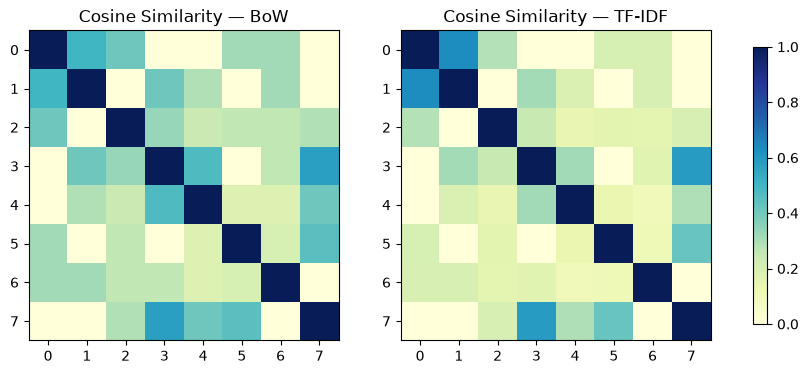

In [12]:
# ── Cell 10: Ma trận cosine và heatmap (TF-IDF) ───────────────────────────
cos_tfidf = cosine_similarity(X_tfidf)
cos_bow = cosine_similarity(X_bow)

print("Cosine Similarity Matrix (TF-IDF):")
print(np.round(cos_tfidf, 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, M_, title in ((axes[0], cos_bow, 'BoW'), (axes[1], cos_tfidf, 'TF-IDF')):
    im = ax.imshow(M_, vmin=0, vmax=1, cmap='YlGnBu')
    ax.set_title(f'Cosine Similarity — {title}')
    ax.set_xticks(range(len(corpus))); ax.set_yticks(range(len(corpus)))
plt.colorbar(im, ax=axes, shrink=0.8)
plt.show()

**Biểu đồ trên cho thấy**: Độ tương đồng 8 câu văn. Màu càng xanh càng giống nhau, màu càng vàng sáng càng khác biệt. TF-IDF (phải) lọc nhiễu tốt hơn BoW (trái) nhờ việc giảm trọng số các từ xuất hiện quá nhiều, giúp làm nổi bật rõ ràng các từ khóa đặc trưng thực sự có ý nghĩa.

In [11]:
# ── Cell 11: Các cặp giống nhau nhất: BoW so với TF-IDF ───────────────────
def top_pairs(S, k=5):
    pairs = [(i, j, S[i, j]) for i in range(len(S)) for j in range(i + 1, len(S))]
    return sorted(pairs, key=lambda p: -p[2])[:k]

for name, S in (('BoW', cos_bow), ('TF-IDF', cos_tfidf)):
    print(f"--- Top 5 cặp giống nhau nhất ({name}) ---")
    for i, j, s in top_pairs(S):
        print(f"  {s:.3f}  [{i}] {corpus[i]!r}  &  [{j}] {corpus[j]!r}")

--- Top 5 cặp giống nhau nhất (BoW) ---
  0.577  [3] 'AI is powerful'  &  [7] 'Deep learning is powerful'
  0.500  [0] 'I love NLP'  &  [1] 'I love AI'
  0.471  [3] 'AI is powerful'  &  [4] 'Machine learning is part of AI'
  0.447  [5] 'Deep learning belongs to NLP'  &  [7] 'Deep learning is powerful'
  0.408  [4] 'Machine learning is part of AI'  &  [7] 'Deep learning is powerful'
--- Top 5 cặp giống nhau nhất (TF-IDF) ---
  0.636  [0] 'I love NLP'  &  [1] 'I love AI'
  0.590  [3] 'AI is powerful'  &  [7] 'Deep learning is powerful'
  0.422  [5] 'Deep learning belongs to NLP'  &  [7] 'Deep learning is powerful'
  0.315  [3] 'AI is powerful'  &  [4] 'Machine learning is part of AI'
  0.312  [1] 'I love AI'  &  [3] 'AI is powerful'


### Trả lời Bài 3
1. **Cặp giống nhau nhất.** Theo TF-IDF: **"I love NLP" và "I love AI"** (cosine **0,636**), kế đến "AI is powerful" và "Deep learning is powerful" (0,590). Điểm cần sửa so với bản trước: hai câu đầu **không** chia sẻ "I" và "love". `CountVectorizer`/`TfidfVectorizer` mặc định bỏ token một ký tự nên "I" không có trong vocabulary; mỗi câu chỉ còn hai từ (`love`, `nlp` hoặc `love`, `ai`) và hai câu **chỉ chung đúng một từ là `love`**. Cosine ≈ 0,64 là vì mỗi vector chỉ có hai thành phần nên một từ chung đã chiếm phần lớn.
2. **So sánh BoW và TF-IDF (có số liệu ở cell trên).**
   - Với BoW, cặp cao nhất là "AI is powerful" và "Deep learning is powerful" (0,577), vì hai câu chung hai từ `is` và `powerful`, và BoW coi `is` (từ rất thông dụng) có giá trị ngang từ khoá. Cặp "I love NLP" – "I love AI" chỉ đạt 0,500.
   - Với TF-IDF, cặp "I love NLP" – "I love AI" lên đầu (0,636) vì từ chung `love` có IDF cao hơn (2,10; hiếm hơn) còn `is` bị giảm trọng số (1,59); cặp "powerful" tụt xuống 0,590.
   - Vậy **TF-IDF đổi thứ hạng** so với BoW đúng theo hướng giảm ảnh hưởng của từ phổ biến như `is`. Chênh lệch giữa hai cặp đầu chỉ là vài phần trăm trên corpus 8 câu rất nhỏ, nên đây là minh hoạ cơ chế chứ không phải bằng chứng TF-IDF "đúng ngữ nghĩa hơn".
3. Cosine chỉ đo trùng từ (không hiểu nghĩa): hai câu cùng chủ đề nhưng khác từ vẫn cho cosine thấp.

## Phần 7 — Phân loại văn bản AI/NLP (TF-IDF + Logistic Regression)
Chỉ có 6 văn bản, nên chia train/test 4/2 rất bất ổn. Ở đây: (a) giữ cách chia cũ để thấy lỗi, (b) dùng `stratify` để mỗi lớp có mặt ở tập test, (c) dùng **leave-one-out** (huấn luyện trên 5 câu, kiểm tra trên 1 câu, lặp 6 lần). TF-IDF được fit **bên trong** pipeline để tập kiểm tra không rò rỉ vào vocabulary.

In [13]:
# ── Cell 12: Dữ liệu phân loại ────────────────────────────────────────────
texts = [
    "I love NLP",
    "Deep learning in NLP",
    "AI is powerful",
    "Machine learning in AI",
    "NLP is interesting",
    "AI changes the world"
]
labels = np.array(["NLP", "NLP", "AI", "AI", "NLP", "AI"])
pipe = make_pipeline(TfidfVectorizer(), LogisticRegression())

In [ ]:
# ── Cell 13: (a) Cách chia cũ: test_size=0.3, không stratify ──────────────
X_all = TfidfVectorizer().fit_transform(texts)
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_all, labels, test_size=0.3, random_state=42)

print("Nhãn tập test:", ya_te.tolist(), "-> tập train chỉ còn:", sorted(set(ya_tr)) , "và", ya_tr.tolist())
print("Mỗi lớp trong train:", {l: int((ya_tr == l).sum()) for l in sorted(set(labels))})
model_a = LogisticRegression().fit(Xa_tr, ya_tr)
print('Dự đoán trên test:', model_a.predict(Xa_te).tolist(), '| Accuracy:', accuracy_score(ya_te, model_a.predict(Xa_te)))

Nhãn tập test: ['NLP', 'NLP'] -> tập train chỉ còn: [np.str_('AI'), np.str_('NLP')] và ['AI', 'AI', 'NLP', 'AI']
Mỗi lớp trong train: {np.str_('AI'): 3, np.str_('NLP'): 1}
Dự đoán trên test: ['AI', 'AI'] | Accuracy: 0.0


In [15]:
# ── Cell 14: (b) Chia có stratify ─────────────────────────────────────────
t_tr, t_te, y_tr, y_te = train_test_split(texts, labels, test_size=2, random_state=42, stratify=labels)
pipe.fit(t_tr, y_tr)
pred = pipe.predict(t_te)
for t, y, p in zip(t_te, y_te, pred):
    print(f"thật={y:<3} dự đoán={p:<3} | {t}")
print("Accuracy:", accuracy_score(y_te, pred), "(chỉ 2 mẫu test: không đủ để kết luận)")

thật=NLP dự đoán=NLP | I love NLP
thật=AI  dự đoán=AI  | AI changes the world
Accuracy: 1.0 (chỉ 2 mẫu test: không đủ để kết luận)


In [16]:
# ── Cell 15: (c) Leave-one-out cross-validation ───────────────────────────
pred_loo = cross_val_predict(pipe, texts, labels, cv=LeaveOneOut())
for t, y, p in zip(texts, labels, pred_loo):
    print(f"{'đúng' if y == p else 'SAI ':<4} thật={y:<3} dự đoán={p:<3} | {t}")
print("Accuracy LOO:", round(accuracy_score(labels, pred_loo), 3))
print(classification_report(labels, pred_loo, zero_division=0))

đúng thật=NLP dự đoán=NLP | I love NLP
SAI  thật=NLP dự đoán=AI  | Deep learning in NLP
SAI  thật=AI  dự đoán=NLP | AI is powerful
SAI  thật=AI  dự đoán=NLP | Machine learning in AI
SAI  thật=NLP dự đoán=AI  | NLP is interesting
đúng thật=AI  dự đoán=AI  | AI changes the world
Accuracy LOO: 0.333
              precision    recall  f1-score   support

          AI       0.33      0.33      0.33         3
         NLP       0.33      0.33      0.33         3

    accuracy                           0.33         6
   macro avg       0.33      0.33      0.33         6
weighted avg       0.33      0.33      0.33         6



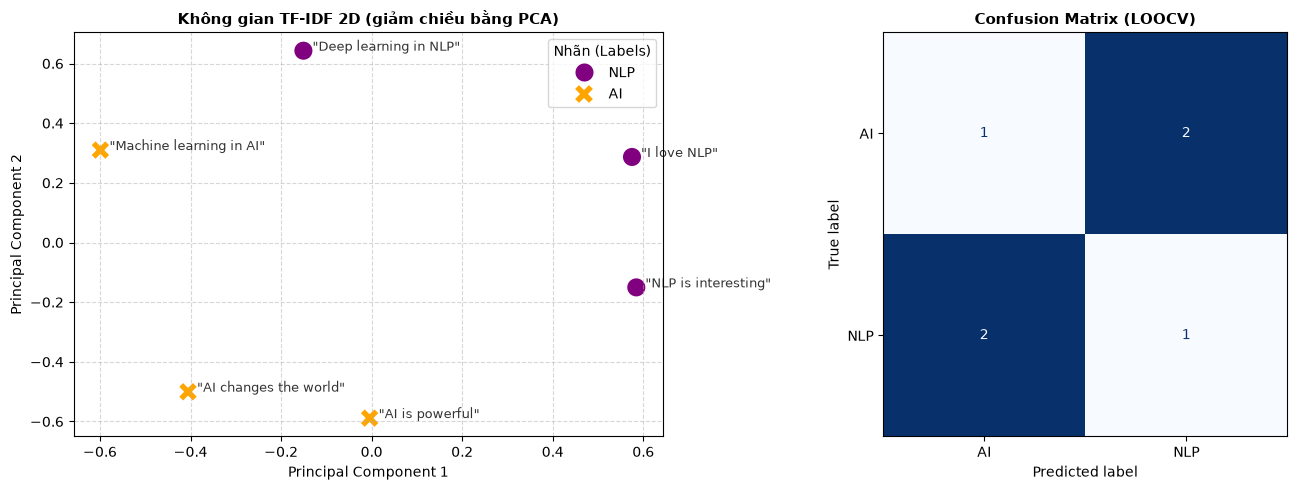

In [17]:
# ── Cell 15: (d) Trực quan hóa không gian văn bản & Confusion Matrix ─────
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Thiết lập hiển thị tiếng Việt và style cho đẹp mắt
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.figure(figsize=(14, 5))

# 1. Biểu đồ 1: Không gian TF-IDF thu gọn 2 chiều (PCA)
plt.subplot(1, 2, 1)
X_dense = X_all.toarray()
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_dense)

# Vẽ biểu đồ tán xạ phân loại AI và NLP
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], 
    hue=labels, style=labels, s=200, palette={"AI": "orange", "NLP": "purple"}
)

# Gắn nhãn câu văn trực tiếp lên điểm dữ liệu
for i, text in enumerate(texts):
    plt.annotate(f'"{text}"', (X_pca[i, 0] + 0.02, X_pca[i, 1]), fontsize=9, alpha=0.8)

plt.title("Không gian TF-IDF 2D (giảm chiều bằng PCA)", fontsize=11, fontweight='bold')
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Nhãn (Labels)")

# 2. Biểu đồ 2: Confusion Matrix cho phương pháp Leave-One-Out CV
plt.subplot(1, 2, 2)
cm = confusion_matrix(labels, pred_loo)
# Sắp xếp nhãn để đồng bộ
classes_sorted = sorted(list(set(labels)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes_sorted)
disp.plot(cmap=plt.cm.Blues, ax=plt.gca(), colorbar=False, values_format='d')

plt.title("Confusion Matrix (LOOCV)", fontsize=11, fontweight='bold')
plt.grid(False) # Tắt lưới của Confusion Matrix cho gọn

plt.tight_layout()
plt.show()

### Nhận xét
- **Vì sao Accuracy = 0,0 ở bản cũ.** Với `test_size=0.3` trên 6 văn bản, tập test có 2 câu. Cách chia không stratify cho tập test gồm hai câu cùng nhãn NLP, và tập train chỉ còn 1 câu NLP so với 3 câu AI (xem cell (a)), nên mô hình thiên về lớp AI và dự đoán sai cả hai. Cảnh báo `UndefinedMetricWarning` xuất hiện vì lớp AI không có mẫu thật trong test và lớp NLP không được dự đoán lần nào.
- **Con số 0,0 không nói lên chất lượng mô hình.** Chỉ cần đổi cách chia (cell (b), có stratify) là 2/2 mẫu đúng, nhưng 2 mẫu cũng không đủ để kết luận gì.
- **Đánh giá hợp lý hơn trên dữ liệu bé là leave-one-out** (cell (c)): Accuracy chỉ khoảng 0,33, tức mô hình **không** học được quy luật đáng tin cậy từ 5 câu. Đây là kết quả trung thực: cần nhiều dữ liệu hơn thì mới có thể đánh giá.